# PL6 · IA Generativa
## Pré-treino e pós-treino na prática (120 min)

**Mestrado em IA · Prática Laboratorial**

Nesta sessão vai reproduzir, em ponto pequeno, as decisões centrais do pipeline de um LLM:

| Parte | Exercício | Tempo | GPU |
|---|---|---|---|
| A · Pré-treino | 1. Curadoria: filtros heurísticos, deduplicação exata e MinHash-LSH | 25 min | não |
| | 2. Filtro de qualidade com classificador + contas de escala | 15 min | opcional |
| B · Pós-treino | 3. DPO de raiz: log-probabilidades, perda e um passo de gradiente | 20 min | sim |
| | 4. DPO com TRL + LoRA e análise das métricas | 25 min | sim |
| | 5. GRPO com recompensas verificáveis (GSM8K) | 20 min | sim |

**Ambiente recomendado:** Google Colab com GPU T4 (16 GB) — *Ambiente de execução → Alterar tipo → T4 GPU*.

**Convenções**
- `# TODO` assinala código a completar; as células seguintes têm `assert` para verificar a solução.
- ✍️ assinala perguntas a responder por escrito na própria célula (contam para a avaliação).
- Os tempos de treino indicados assumem uma T4; se ficar atrasado, reduza `max_steps`.

## 0 · Preparação (≈ 5 min)

In [ ]:
# Instalação no Colab (≈ 1–2 min). Se o Colab pedir para reiniciar a sessão, reinicie e continue na célula seguinte.
!pip -q install "trl==0.19.1" "peft>=0.15" "datasets>=3.0" "datasketch>=1.6" accelerate

In [ ]:
import os, re, math, random, time, zlib, hashlib, gc
from collections import Counter, defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn.functional as F

SEMENTE = 0
random.seed(SEMENTE); np.random.seed(SEMENTE); torch.manual_seed(SEMENTE)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sem GPU: as Partes 3–5 vão ser muito lentas)")

Dispositivo: cuda Tesla T4


---
# PARTE A · PRÉ-TREINO

## 1 · Curadoria de um corpus web (≈ 25 min)

Vamos usar ~3 000 documentos em português do **FineWeb-2** (`por_Latn`). Como este corpus **já foi filtrado e deduplicado**, vamos **injetar corrupção controlada** para termos verdade de base:

- 50 **duplicados exatos**;
- 100 **quase-duplicados** (palavras apagadas ou trocadas com uma dada taxa);
- 50 documentos **lixo** (menus, hashtags, repetição, *lorem ipsum*).

Assim conseguimos medir *precisão* e *recall* de cada etapa do funil.

In [ ]:
from datasets import load_dataset

N_DOCS = 3000

def corpus_sintetico(n=N_DOCS, seed=0):
    """Plano B (sem internet): pseudo-texto com vocabulário português."""
    rng = random.Random(seed)
    vocab = ("o a de que e do da em um para com não uma os no se na por mais as dos como mas foi ao ele das tem "
             "seu sua ou ser quando muito há nos já está também só pelo pela até isso ela entre era depois sem mesmo "
             "cidade governo universidade estudo dados modelo sistema projeto trabalho tempo ano país mundo forma parte "
             "vida história caso problema lugar empresa grupo região investigação resultado processo").split()
    docs = []
    for _ in range(n):
        alvo, frases, w = rng.randint(30, 600), [], 0
        while w < alvo:
            k = rng.randint(6, 20); w += k
            frases.append(" ".join(rng.choice(vocab) for _ in range(k)).capitalize() + ".")
        docs.append(" ".join(frases))
    return docs

def carregar_corpus(n=N_DOCS):
    for nome, cfg in [("HuggingFaceFW/fineweb-2", "por_Latn"), ("HuggingFaceFW/fineweb", "sample-10BT")]:
        try:
            ds = load_dataset(nome, name=cfg, split="train", streaming=True)
            docs = [x["text"] for _, x in zip(range(n), ds)]
            print(f"Carregados {len(docs)} documentos de {nome} [{cfg}]")
            return docs
        except Exception as e:
            print(f"Falhou {nome} [{cfg}]: {type(e).__name__}")
    print("A usar corpus sintético (resultados qualitativamente semelhantes, textos sem sentido).")
    return corpus_sintetico(n)

docs = carregar_corpus()
print("Palavras por documento (mediana):", int(np.median([len(d.split()) for d in docs])))

README.md:   0%|          | 0.00/329k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

Carregados 3000 documentos de HuggingFaceFW/fineweb-2 [por_Latn]
Palavras por documento (mediana): 268


In [ ]:
def quase_duplicado(texto, taxa, rng):
    """Apaga (taxa/2) ou substitui (taxa/2) cada palavra com probabilidade `taxa`."""
    palavras, out = texto.split(), []
    for p in palavras:
        u = rng.random()
        if u < taxa / 2:   continue
        elif u < taxa:     out.append(rng.choice(palavras))
        else:              out.append(p)
    return " ".join(out)

LIXO = [
    lambda rng: "\n".join("• " + rng.choice(["Início", "Contactos", "Loja", "Login", "Carrinho", "Termos", "Privacidade"]) for _ in range(40)),
    lambda rng: " ".join(rng.choice(["#promo", "#oferta", "...", "$$$", "#grátis", "#top"]) for _ in range(200)),
    lambda rng: "clique aqui para saber mais " * 40,
    lambda rng: "Lorem ipsum dolor sit amet, consectetur adipiscing elit. " * 20,
]

def corromper(docs, n_exatos=50, n_quase=100, n_lixo=50, taxa=0.02, seed=0):
    rng = random.Random(seed)
    corpus = [{"id": i, "texto": t, "tipo": "original", "origem": None} for i, t in enumerate(docs)]
    base = [d for d in corpus if len(d["texto"].split()) >= 100]
    for _ in range(n_exatos):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": d["texto"], "tipo": "exato", "origem": d["id"]})
    for _ in range(n_quase):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": quase_duplicado(d["texto"], taxa, rng), "tipo": "quase", "origem": d["id"]})
    for _ in range(n_lixo):
        corpus.append({"id": len(corpus), "texto": rng.choice(LIXO)(rng), "tipo": "lixo", "origem": None})
    rng.shuffle(corpus)
    return corpus

corpus = corromper(docs)
print(pd.Series([d["tipo"] for d in corpus]).value_counts())

original    3000
quase        100
lixo          50
exato         50
Name: count, dtype: int64


### 1.1 · Filtros heurísticos (estilo Gopher / C4)

Complete as regras em falta. Referência (Rae et al., 2021): 50–100 000 palavras; comprimento médio das palavras entre 3 e 10; rácio símbolos/palavras ≤ 0,1 (contar `#`, `...` e `…`); ≤ 90 % das linhas a começar por marcador; ≤ 30 % das linhas a acabar em reticências; ≥ 80 % das palavras com pelo menos uma letra; pelo menos 2 *stopwords*. E um filtro de repetição: a fração de caracteres ocupada pelo bigrama mais frequente deve ser ≤ 0,20.

In [ ]:
STOP = {"de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com", "não", "uma", "os", "no", "se", "na", "por",
        "the", "be", "to", "of", "and", "that", "have", "with"}

def filtro_gopher(texto, stop=STOP):
    palavras = texto.split()
    n = len(palavras)
    if not (50 <= n <= 100_000):
        return False, "n_palavras"
    # TODO: implemente as regras de comprimento médio, símbolos, marcadores, reticências, palavras alfabéticas e stopwords (devolva (False, "nome_da_regra"))
    # Regras heurísticas: comprimento médio, símbolos, linhas, palavras e stopwords.
    media = sum(len(p) for p in palavras) / n
    if not (3 <= media <= 10):
        return False, "comprimento_medio"

    simbolos = texto.count("#") + texto.count("...") + texto.count("…")
    if simbolos / n > 0.1:
        return False, "simbolos"

    linhas = [linha for linha in texto.splitlines() if linha.strip()]
    marcador = re.compile(r"^\s*(?:[-*+•▪◦‣]|#{1,6}\s|\d+[.)]\s)")
    if linhas and sum(bool(marcador.match(linha)) for linha in linhas) / len(linhas) > 0.9:
        return False, "marcadores"

    if linhas and sum(bool(re.search(r"(?:\.\.\.|…)\s*$", linha)) for linha in linhas) / len(linhas) > 0.3:
        return False, "reticencias"

    if sum(any(letra.isalpha() for letra in p) for p in palavras) / n < 0.8:
        return False, "palavras_alfabeticas"

    tokens = re.findall(r"\b\w+\b", texto.lower())
    if len(set(tokens) & stop) < 2:
        return False, "stopwords"

    return True, "ok"


def frac_top_ngrama(texto, n=2):
    p = texto.lower().split()
    grams = [" ".join(p[i:i + n]) for i in range(len(p) - n + 1)]
    if not grams:
        return 0.0
    g, c = Counter(grams).most_common(1)[0]
    return c * len(g.replace(" ", "")) / max(1, sum(len(x) for x in p))

def filtro_repeticao(texto, limiar=0.20):
    # TODO: use frac_top_ngrama para rejeitar documentos repetitivos
    # Rejeita documentos em que o bigrama mais frequente excede o limiar.
    fracao = frac_top_ngrama(texto)
    return fracao <= limiar, "ok" if fracao <= limiar else "repeticao"

def aplicar_filtros(texto):
    ok, motivo = filtro_gopher(texto)
    if not ok:
        return motivo
    ok, motivo = filtro_repeticao(texto)
    return "ok" if ok else motivo

In [ ]:
for d in corpus:
    d["filtro"] = aplicar_filtros(d["texto"])
tab = pd.crosstab(pd.Series([d["tipo"] for d in corpus], name="tipo"), pd.Series([d["filtro"] for d in corpus], name="resultado"))
display(tab)

lixo = [d for d in corpus if d["tipo"] == "lixo"]
assert sum(d["filtro"] != "ok" for d in lixo) == len(lixo), "Todo o lixo injetado devia ser removido pelos filtros."
print("✔ Todo o lixo foi removido.")

resultado,marcadores,ok,reticencias,simbolos,stopwords
tipo,,,,,
exato,0,50,0,0,0
lixo,8,0,0,18,24
original,0,2999,0,1,0
quase,2,96,2,0,0


✔ Todo o lixo foi removido.


✍️ **P1.1** Que regras removem cada tipo de lixo? Há documentos *originais* removidos? Mostre 2 exemplos e discuta se são falsos positivos ou lixo real.

**✍️ Resposta:** Na tabela guardada, os 50 duplicados exatos passam os filtros; o lixo foi todo removido: 8 documentos pela regra dos marcadores, 18 pelo excesso de símbolos e 24 pela falta de stopwords. Entre os originais, 2999 passaram e apenas 1 foi removido, pela regra simbolos. O exemplo disponível começa por “Muito bem…apos longo tempo de ausencia… Arranjei uma casinha nova…”, um texto informal de blog com muitas reticências; parece um falso positivo, não lixo real. Como só foi removido um original nesta execução, não há dois exemplos de originais removidos, apesar do que pede o enunciado. Para contraste, o lixo injetado inclui menus em lista (removidos por marcadores) e sequências como #promo/... (removidas por simbolos).

In [ ]:
for d in [d for d in corpus if d["tipo"] == "original" and d["filtro"] != "ok"][:2]:
    print(f'[{d["filtro"]}]', d["texto"][:300].replace("\n", " ⏎ "), "\n")

[simbolos] Muito bem…apos longo tempo de ausencia… ⏎ Arranjei uma casinha nova…. ⏎ Ja a tenho a algum tempo… Mas ainda esta a meio gás… ⏎ Se por acaso alguma alma quiser la ir dar um salto é so ir a ⏎ e ja agora ⏎ Se querem um blog virado pa informatica…têm aqui o blog do “meu patrão” ⏎ Que como “bom patrao” que é…anda me 



### 1.2 · Deduplicação exata

Normalize o texto (minúsculas, espaços colapsados), calcule um hash e mantenha, em cada grupo, o documento com **menor `id`** (o original).

In [ ]:
def normalizar(texto):
    # TODO: minúsculas e espaços colapsados
    return " ".join(texto.lower().split())

def dedup_exata(docs_):
    grupos = defaultdict(list)
    for d in docs_:
        grupos[hashlib.md5(normalizar(d["texto"]).encode()).hexdigest()].append(d)
    manter = {min(g, key=lambda d: d["id"])["id"] for g in grupos.values()}
    return [d for d in docs_ if d["id"] in manter], [d for d in docs_ if d["id"] not in manter]

apos_filtros = [d for d in corpus if d["filtro"] == "ok"]
apos_exata, removidos = dedup_exata(apos_filtros)
print(f"{len(apos_filtros)} → {len(apos_exata)} documentos;", Counter(d["tipo"] for d in removidos))
assert Counter(d["tipo"] for d in removidos)["exato"] == 50

3145 → 3094 documentos; Counter({'exato': 50, 'quase': 1})


### 1.3 · MinHash de raiz

Para dois conjuntos de *shingles* (5-gramas de palavras) $A$ e $B$:

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|},\qquad P\big[\min h(A)=\min h(B)\big]=J(A,B)$$

Implemente a assinatura com $k$ funções de hash universais $h_j(x)=(a_j x+b_j) \bmod p$ e verifique que a fração de posições iguais estima $J$.

In [ ]:
def shingles(texto, n=5):
    p = re.findall(r"\w+", texto.lower())
    return {" ".join(p[i:i + n]) for i in range(max(1, len(p) - n + 1))}

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

P_PRIMO = np.uint64(4294967311)  # primo > 2^32
def assinatura_minhash(sh, k=112, seed=1):
    rng = np.random.default_rng(seed)               # a mesma semente para todos os documentos!
    a = rng.integers(1, 2**31, size=k, dtype=np.uint64)
    b = rng.integers(0, 2**31, size=k, dtype=np.uint64)
    x = np.fromiter((zlib.crc32(s.encode()) for s in sh), dtype=np.uint64, count=len(sh))
    # TODO: calcule h_j(x) para todos os shingles e todas as funções e devolva o mínimo por função (vetor de k inteiros)
    if len(x) == 0:
        return np.full(k, P_PRIMO, dtype=np.uint64)
    hashes = (a[:, None] * x[None, :] + b[:, None]) % P_PRIMO
    return hashes.min(axis=1)

def jaccard_estimado(s1, s2):
    return float(np.mean(s1 == s2))

In [ ]:
rng = random.Random(1)
base = [d["texto"] for d in apos_exata if len(d["texto"].split()) >= 150]
linhas = []
for taxa in [0.01, 0.03, 0.05, 0.10, 0.20]:
    for _ in range(5):
        a = rng.choice(base); b = quase_duplicado(a, taxa, rng)
        sa, sb = shingles(a), shingles(b)
        for k in [16, 112, 512]:
            linhas.append({"taxa": taxa, "k": k, "J_exato": jaccard(sa, sb),
                           "J_estimado": jaccard_estimado(assinatura_minhash(sa, k), assinatura_minhash(sb, k))})
res = pd.DataFrame(linhas); res["erro_abs"] = (res.J_estimado - res.J_exato).abs()
display(res.groupby("k").erro_abs.mean().rename("erro absoluto médio"))
assert res[res.k == 512].erro_abs.mean() < 0.05

,erro absoluto médio
k,
16,0.067333
112,0.022712
512,0.011285


✍️ **P1.2** Como varia o erro com $k$? Relacione com o desvio-padrão do estimador, $\sqrt{J(1-J)/k}$. Porque é que 5 % de palavras alteradas dão um $J$ tão baixo?

**✍️ Resposta:** O erro absoluto médio diminuiu nos outputs guardados: 0,067 para k=16, 0,023 para k=112 e 0,011 para k=512. Isto é consistente com o desvio-padrão do estimador, $\sqrt{J(1-J)/k}$, que decresce como $1/\sqrt{k}$ (passar de k=16 para k=512 reduz o desvio por um fator $\sqrt{32}\approx5{,}7$, próximo do observado, ≈6). Com 5 % de palavras alteradas, cada alteração destrói até cinco shingles consecutivos de 5 palavras; a probabilidade de um shingle ficar intacto é cerca de $0{,}95^5\approx0{,}77$, o que dá $J\approx0{,}77/(2-0{,}77)\approx0{,}63$, bastante abaixo de 0,95.

### 1.4 · LSH por bandas e curva em S

Divida a assinatura em $b$ bandas de $r$ linhas: dois documentos são **candidatos** se coincidirem em **todas** as linhas de **pelo menos uma** banda. Teoricamente:

$$P(\text{candidato}\mid s)=1-(1-s^{r})^{b}$$

O FineWeb usa $b=14$, $r=8$ ($k=112$).

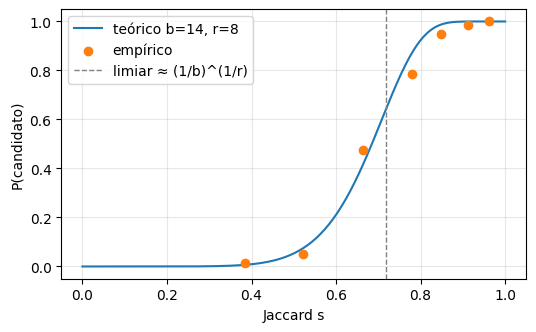

In [ ]:
def candidato_lsh(s1, s2, b=14, r=8):
    assert len(s1) == len(s2) == b * r
    # TODO: devolva True se alguma banda for idêntica nas duas assinaturas
    return any(
        all(s1[inicio + i] == s2[inicio + i] for i in range(r))
        for inicio in range(0, b * r, r)
    )

def p_teorico(s, b=14, r=8):
    return 1 - (1 - s ** r) ** b

rng = random.Random(2)
pontos = []
for taxa in [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12]:
    Js, det = [], 0
    for _ in range(80):
        a = rng.choice(base); bq = quase_duplicado(a, taxa, rng)
        sa, sb = shingles(a), shingles(bq)
        Js.append(jaccard(sa, sb)); det += candidato_lsh(assinatura_minhash(sa), assinatura_minhash(sb))
    pontos.append((np.mean(Js), det / 80))

s = np.linspace(0, 1, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(s, p_teorico(s), label="teórico b=14, r=8")
plt.scatter(*zip(*pontos), color="C1", zorder=3, label="empírico")
plt.axvline((1 / 14) ** (1 / 8), ls="--", c="gray", lw=1, label="limiar ≈ (1/b)^(1/r)")
plt.xlabel("Jaccard s"); plt.ylabel("P(candidato)"); plt.legend(); plt.grid(alpha=.3); plt.show()

✍️ **P1.3** Os pontos empíricos seguem a curva? A partir de que taxa de edição os quase-duplicados deixam de ser apanhados? Que $(b,r)$ escolheria para apanhar $s\ge 0{,}6$ com o mesmo $k=112$?

**✍️ Resposta:** Sim, os pontos empíricos acompanham a curva teórica em S (com variação natural por terem sido usados 80 pares por taxa): a probabilidade de ser candidato é ≈1 para $s\gtrsim0{,}85$, cai para ≈0,78 com 3 % de edição ($s\approx0{,}78$), para ≈0,47 com 5 % ($s\approx0{,}67$) e fica perto de 0,05 com 8 % ($s\approx0{,}52$) e de 0 com 12 %. Ou seja, a deteção deixa de ser fiável a partir de ~3–5 % de palavras alteradas e é praticamente nula a partir de ~8 % (os shingles de 5 palavras amplificam as edições). Para manter k=112 e detetar $s\ge0{,}6$, escolheria b=28, r=4: em s=0,6, $1-(1-0{,}6^4)^{28}\approx0{,}98$, à custa de mais falsos positivos para pares menos semelhantes.

### 1.5 · Deduplicação à escala do corpus (datasketch)

In [ ]:
from datasketch import MinHash, MinHashLSH

def minhash_ds(sh, k=112):
    m = MinHash(num_perm=k, seed=1)
    m.update_batch([s.encode("utf8") for s in sh])
    return m

def dedup_quase(docs_, b=14, r=8):
    lsh, mhs = MinHashLSH(num_perm=b * r, params=(b, r)), {}
    for d in docs_:
        mhs[d["id"]] = minhash_ds(shingles(d["texto"]), b * r); lsh.insert(d["id"], mhs[d["id"]])
    pai = {d["id"]: d["id"] for d in docs_}
    def raiz(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]; x = pai[x]
        return x
    for d in docs_:
        for c in lsh.query(mhs[d["id"]]):
            ra, rb = raiz(d["id"]), raiz(c)
            if ra != rb: pai[max(ra, rb)] = min(ra, rb)   # o representante é o menor id
    grupo = {d["id"]: raiz(d["id"]) for d in docs_}
    return [d for d in docs_ if grupo[d["id"]] == d["id"]], grupo

t0 = time.time()
final, grupo = dedup_quase(apos_exata)
quase = [d for d in apos_exata if d["tipo"] == "quase"]
recall = np.mean([grupo[d["id"]] != d["id"] for d in quase])
orig_rem = [d for d in apos_exata if d["tipo"] == "original" and grupo[d["id"]] != d["id"]]
print(f"{len(apos_exata)} → {len(final)} documentos em {time.time() - t0:.0f}s")
print(f"Recall nos quase-duplicados injetados: {recall:.1%}  |  originais removidos: {len(orig_rem)}")

3094 → 3005 documentos em 5s
Recall nos quase-duplicados injetados: 93.7%  |  originais removidos: 0


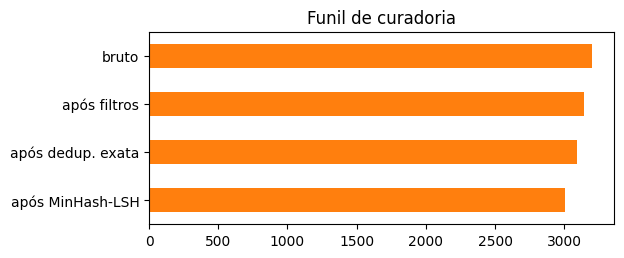

In [ ]:
# Funil completo
funil = pd.Series({"bruto": len(corpus), "após filtros": len(apos_filtros), "após dedup. exata": len(apos_exata), "após MinHash-LSH": len(final)})
funil.plot.barh(figsize=(6, 2.5), color="C1"); plt.gca().invert_yaxis(); plt.title("Funil de curadoria"); plt.show()
for d in orig_rem[:2]:
    rep = next(x for x in apos_exata if x["id"] == grupo[d["id"]])
    print(f'J = {jaccard(shingles(d["texto"]), shingles(rep["texto"])):.2f}\n  A: {d["texto"][:160]!r}\n  B: {rep["texto"][:160]!r}\n')

✍️ **P1.4** Os originais removidos pelo MinHash são erros ou duplicados *naturais* do corpus? O que mudaria se a deduplicação fosse global sobre vários *snapshots* do Common Crawl (recorde o resultado do FineWeb)?

**✍️ Resposta:** O output mostra 3094 documentos após a deduplicação exata e 3005 após o MinHash-LSH: foram agrupados 89 documentos, com recall de 93,7 % nos quase-duplicados injetados e **zero originais removidos**. Portanto, nesta amostra os documentos removidos são quase-duplicados injetados e não há erros a analisar; num corpus real, pares legítimos muito semelhantes (por exemplo, o mesmo comunicado republicado em vários sites) seriam agrupados e podem ser considerados duplicados *naturais* e não erros do método.

## 2 · Filtro de qualidade e contas de escala (≈ 15 min)

### 2.1 · Classificador educativo do FineWeb-Edu

O `HuggingFaceFW/fineweb-edu-classifier` é um regressor (embeddings Snowflake-Arctic + cabeça linear) treinado com ~450 mil notas 0–5 atribuídas pelo Llama-3-70B. O FineWeb-Edu mantém os documentos com nota arredondada ≥ 3.

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/44.3k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

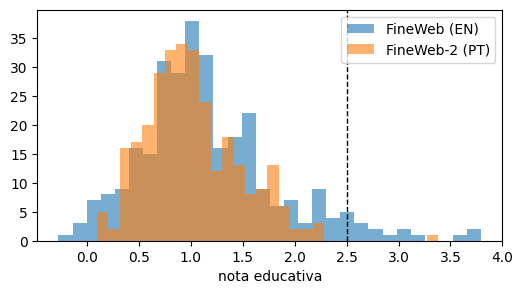

Fração com nota ≥ 3 — EN: 4.7% | PT: 0.3%

[3.69] Was The Race To The Moon Real?; June 1994; Scientific American Magazine; by Logsdon, Dupas; 8 Page(s) Twenty-five years ago, on July 20, 1969, Neil A. Armstrong took the first footsteps on the surface of the moon. That event marked a political and te

[3.80] Imagine a human spacecraft crew voyaging through space. A satellite sends a warning; energetic particles are being accelerated from the sun's corona, sending dangerous radiation toward their spacecraft, but the crew isn't worried. Long before their j

[-0.27] Short Dressesfrom £39 FURTHER REDUCTIONSShop All Sale Jackets & Coatsfrom £35 Our New In pieces are perfect to keep your wardrobe refreshed. Find a look you love in our latest lookbooks. Join the party on social media and get the lowdown on all thing

[-0.05] Her warm-weather faves, with a glittery new look she'll flip for! - Soft rubber footbeds are coated with sugar glitter - Flexible transparent plastic straps are infused wi

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
CLS = "HuggingFaceFW/fineweb-edu-classifier"
tok_c = AutoTokenizer.from_pretrained(CLS)
clf = AutoModelForSequenceClassification.from_pretrained(CLS).to(DEVICE).eval()

@torch.no_grad()
def nota_edu(textos, bs=16):
    notas = []
    for i in range(0, len(textos), bs):
        enc = tok_c(textos[i:i + bs], return_tensors="pt", padding="longest", truncation=True, max_length=512).to(DEVICE)
        notas += clf(**enc).logits.squeeze(-1).float().cpu().tolist()
    return np.array(notas)

en = load_dataset("HuggingFaceFW/fineweb", name="sample-10BT", split="train", streaming=True)
docs_en = [x["text"] for _, x in zip(range(300), en)]
notas_en = nota_edu(docs_en)
notas_pt = nota_edu([d["texto"] for d in final[:300]])

plt.figure(figsize=(6, 3)); plt.hist(notas_en, bins=30, alpha=.6, label="FineWeb (EN)"); plt.hist(notas_pt, bins=30, alpha=.6, label="FineWeb-2 (PT)")
plt.axvline(2.5, c="k", ls="--", lw=1); plt.legend(); plt.xlabel("nota educativa"); plt.show()
print(f"Fração com nota ≥ 3 — EN: {(notas_en >= 2.5).mean():.1%} | PT: {(notas_pt >= 2.5).mean():.1%}")
for i in list(np.argsort(notas_en)[-2:]) + list(np.argsort(notas_en)[:2]):
    print(f"\n[{notas_en[i]:.2f}]", docs_en[i][:250].replace("\n", " "))

✍️ **P2.1** Que fração passa o limiar? Que características têm os documentos com nota alta e baixa? O que acontece com os documentos em português e que viés isso introduziria num corpus multilingue?

**✍️ Resposta:** Nos outputs guardados, passaram o limiar 4,7 % dos 300 textos em inglês e 0,3 % dos textos em português. Os dois exemplos ingleses com notas altas eram artigos informativos/científicos; os dois de notas baixas eram páginas comerciais e descrições de produtos. As notas em português concentraram-se quase todas abaixo do limiar, o que sugere viés contra essa língua e pode reduzir a sua representação num corpus multilingue. Aqui foram avaliados textos do FineWeb-2 em português, mas a amostra é de apenas 300 documentos; a diferença observada é um sinal, não uma avaliação conclusiva do classificador.

### 2.2 · Calculadora de pré-treino

Implemente as funções e responda às perguntas. Use o pico denso BF16 da H100 (989 TFLOP/s).

In [ ]:
def flops_treino(N, D):
    # TODO: aproximação C ≈ 6ND
    return 6 * N * D

def dias_treino(N, D, n_gpus, pico=989e12, mfu=0.40):
    # TODO: tempo em dias
    return flops_treino(N, D) / (n_gpus * pico * mfu * 86400)

def memoria_estados_gb(psi, nd=1, estagio=0, K=12):
    """Pesos+gradientes BF16 (2+2 bytes) + estados Adam (K=12 bytes), com ZeRO-0/1/2/3."""
    # TODO: fórmulas do ZeRO (Rajbhandari et al., 2020)
    if nd < 1:
        raise ValueError("nd tem de ser pelo menos 1")
    if estagio == 0:
        bytes_por_parametro = 4 + K
    elif estagio == 1:
        bytes_por_parametro = 4 + K / nd
    elif estagio == 2:
        bytes_por_parametro = 2 + (2 + K) / nd
    elif estagio == 3:
        bytes_por_parametro = (4 + K) / nd
    else:
        raise ValueError("estagio tem de ser 0, 1, 2 ou 3")
    return psi * bytes_por_parametro / 1e9

assert abs(flops_treino(405e9, 15.6e12) / 3.8e25 - 1) < 0.02
assert abs(dias_treino(70e9, 15e12, 2048) - 90) < 2
assert memoria_estados_gb(70e9, 64, 3) == 17.5
print("✔ Calculadora correta")

✔ Calculadora correta


In [ ]:
# Q-a) Quantas H100 para treinar um 8B com 15T tokens em 30 dias com MFU de 40%?
# TODO: calcule n_gpus (arredonde para cima)
n_gpus = math.ceil(flops_treino(8e9, 15e12) / (30 * 86400 * 989e12 * 0.40))
print("GPUs necessárias:", n_gpus)

# Q-b) Afinação completa com Adam numa T4 (16 GB): cabe um 0,5B? E um 7B?
for psi in [0.5e9, 7e9]:
    print(f"{psi/1e9:.1f}B → {memoria_estados_gb(psi):.0f} GB só em estados (sem ativações)")

GPUs necessárias: 703
0.5B → 8 GB só em estados (sem ativações)
7.0B → 112 GB só em estados (sem ativações)


✍️ **P2.2** Interprete os resultados de (a) e (b). Porque é que, nas Partes 4–5, usamos LoRA mesmo num modelo de 0,5B?

**✍️ Resposta:** Para treinar o modelo de 8B parâmetros com 15T tokens em 30 dias, a estimativa é de 703 GPUs H100, mostrando o custo elevado do pré-treino. Na afinação completa, o modelo de 0,5B precisa de cerca de 8 GB só para estados e o de 7B de 112 GB; por isso, o de 7B não cabe numa T4 de 16 GB, e o de 0,5B fica apertado quando se acrescentam ativações e outros custos de memória. Usamos LoRA mesmo com 0,5B porque só treinamos pequenos adaptadores, reduzindo gradientes, estados do otimizador e computação. Os pesos do modelo base e as ativações continuam a ocupar memória, mas a afinação fica bem mais viável.

---
# PARTE B · PÓS-TREINO

## 3 · DPO de raiz (≈ 20 min)

$$\mathcal{L}_{\text{DPO}}=-\log\sigma\!\Big(\beta\log\frac{\pi_\theta(y_w|x)}{\pi_{\text{ref}}(y_w|x)}-\beta\log\frac{\pi_\theta(y_l|x)}{\pi_{\text{ref}}(y_l|x)}\Big)$$

Usamos `Qwen/Qwen2.5-0.5B-Instruct` como política e como referência.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
tok = AutoTokenizer.from_pretrained(MODELO)
politica = AutoModelForCausalLM.from_pretrained(MODELO, dtype=torch.float32).to(DEVICE)
referencia = AutoModelForCausalLM.from_pretrained(MODELO, dtype=torch.float32).to(DEVICE).eval()
for p in referencia.parameters(): p.requires_grad_(False)
print(f"{sum(p.numel() for p in politica.parameters())/1e6:.0f}M parâmetros")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

494M parâmetros


### 3.1 · Log-probabilidade de uma resposta

$\log\pi(y|x)=\sum_t \log\pi(y_t\mid x,y_{<t})$ — **só nos tokens da resposta** (incluindo o fim de turno). Atenção ao desvio de uma posição entre *logits* e alvos.

In [ ]:
def logprob_resposta(modelo, prompt, resposta, grad=False):
    txt_p = tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    ids_p = tok(txt_p, add_special_tokens=False, return_tensors="pt").input_ids
    ids_r = tok(resposta + tok.eos_token, add_special_tokens=False, return_tensors="pt").input_ids
    ids = torch.cat([ids_p, ids_r], dim=1).to(modelo.device)
    with torch.set_grad_enabled(grad):
        logits = modelo(ids).logits[:, :-1].float()          # logits[t] prevê ids[t+1]
        alvo = ids[:, 1:]
        lp = torch.log_softmax(logits, -1).gather(-1, alvo.unsqueeze(-1)).squeeze(-1)
        # TODO: construa a máscara que seleciona só as posições cujo alvo é um token da resposta e devolva a soma
        mascara = torch.arange(alvo.shape[1], device=alvo.device) >= ids_p.shape[1] - 1
        return lp[:, mascara].sum()

### 3.2 · A perda

In [ ]:
def perda_dpo(lp_pol_w, lp_pol_l, lp_ref_w, lp_ref_l, beta=0.1):
    """Devolve (perda, recompensa implícita de y_w, recompensa implícita de y_l)."""
    # TODO: recompensas implícitas r = β·(log π_θ − log π_ref) e perda −log σ(r_w − r_l)
    rw = beta * (lp_pol_w - lp_ref_w)
    rl = beta * (lp_pol_l - lp_ref_l)
    perda = F.softplus(rl - rw)
    return perda, rw, rl

# Verificação com o Exercício II da aula teórica: diferenças +2 e −1, β = 0,1  →  perda ≈ 0,554
L, rw, rl = perda_dpo(torch.tensor(2.), torch.tensor(-1.), torch.tensor(0.), torch.tensor(0.))
assert abs(L.item() - 0.5544) < 1e-3
print(f"perda = {L.item():.4f}   peso do gradiente σ(r_l − r_w) = {torch.sigmoid(rl - rw).item():.3f}")

perda = 0.5544   peso do gradiente σ(r_l − r_w) = 0.426


In [ ]:
PROMPT = "Explica em duas frases o que é a deduplicação de dados no pré-treino de LLMs."
Y_W = ("É a remoção de documentos repetidos ou quase repetidos do corpus de treino. Evita que o modelo memorize "
       "texto duplicado e poupa compute, além de reduzir a contaminação de benchmarks.")
Y_L = "Deduplicação é quando os dados são duplicados para o modelo aprender melhor."

lp = {nome: logprob_resposta(m, PROMPT, y).item() for nome, m, y in
      [("pol_w", politica, Y_W), ("pol_l", politica, Y_L), ("ref_w", referencia, Y_W), ("ref_l", referencia, Y_L)]}
L0, _, _ = perda_dpo(torch.tensor(lp["pol_w"]), torch.tensor(lp["pol_l"]), torch.tensor(lp["ref_w"]), torch.tensor(lp["ref_l"]))
print(lp); print(f"perda inicial = {L0.item():.4f}   (log 2 = {math.log(2):.4f})")

{'pol_w': -137.22607421875, 'pol_l': -64.95844268798828, 'ref_w': -137.22607421875, 'ref_l': -64.95844268798828}
perda inicial = 0.6931   (log 2 = 0.6931)


✍️ **P3.1** Porque é que a perda inicial é exatamente $\log 2$? Qual das duas respostas tem maior $\log\pi$ e porque é que isso **não** significa que o modelo a prefira?

**✍️ Resposta:** A perda inicial é log 2 approx 0,693 porque, no início, a política e o modelo de referência têm as mesmas probabilidades. A resposta curta tem maior log-probabilidade (-64,96 contra -137,22), mas isso acontece sobretudo por ser mais curta. Por isso, o valor absoluto não indica qual resposta é melhor; o DPO compara as respostas com as probabilidades do modelo de referência.

### 3.3 · Dez passos de gradiente num único par

Implemente o ciclo de treino (SGD, `lr=1e-5`) e registe $\log\pi_\theta(y_w)$, $\log\pi_\theta(y_l)$ e a margem.

,passo,perda,logp_w,logp_l,margem
0,0,0.693,-137.226,-64.958,0.000
1,1,0.325,-131.436,-68.748,0.958
2,2,0.210,-128.590,-70.839,1.452
3,3,0.156,-126.746,-72.281,1.780
4,4,0.124,-125.391,-73.385,2.026
5,5,0.103,-124.322,-74.282,2.223
6,6,0.088,-123.441,-75.038,2.386
7,7,0.077,-122.692,-75.692,2.527
8,8,0.068,-122.041,-76.269,2.650
9,9,0.061,-121.466,-76.786,2.759


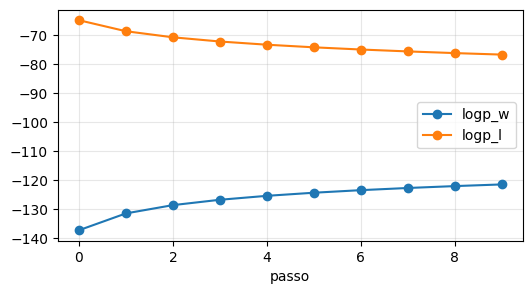

In [ ]:
otim = torch.optim.SGD(politica.parameters(), lr=1e-5)
hist = []
for passo in range(10):
    # TODO: calcule as log-probs com gradiente (política) e sem (referência, já em `lp`), a perda, e dê um passo
    otim.zero_grad(set_to_none=True)
    lw = logprob_resposta(politica, PROMPT, Y_W, grad=True)
    ll = logprob_resposta(politica, PROMPT, Y_L, grad=True)
    ref_w = torch.tensor(lp["ref_w"], device=lw.device)
    ref_l = torch.tensor(lp["ref_l"], device=ll.device)
    perda, rw, rl = perda_dpo(lw, ll, ref_w, ref_l)
    perda.backward()
    otim.step()
    hist.append({"passo": passo, "perda": perda.item(), "logp_w": lw.item(), "logp_l": ll.item(), "margem": (rw - rl).item()})
h = pd.DataFrame(hist); display(h.round(3))
h.plot(x="passo", y=["logp_w", "logp_l"], figsize=(6, 3), marker="o"); plt.grid(alpha=.3); plt.show()

✍️ **P3.2** A margem cresce? O que acontece a $\log\pi_\theta(y_w)$ — sobe, desce ou fica? Relacione com o *deslocamento de verosimilhança* (Razin et al., 2024). Que papel tem $\beta$?

**✍️ Resposta:** Sim, a margem cresce de 0 para 2,759 em 10 passos. Neste par, $\log\pi_\theta(y_w)$ **sobe** (de −137,226 para −121,466) e $\log\pi_\theta(y_l)$ desce (de −64,958 para −76,786), ou seja, a probabilidade desloca-se da resposta rejeitada para a preferida.

In [ ]:
del politica, referencia, otim; gc.collect(); torch.cuda.empty_cache()   # libertar a GPU

## 4 · DPO com TRL + LoRA (≈ 25 min, ~6 min de treino)

Dados: 1 000 pares do `trl-lib/ultrafeedback_binarized`. A referência é o próprio modelo com os adaptadores LoRA desligados.

In [ ]:
!pip install -U -q trl transformers accelerate peft torchao

In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from trl import DPOConfig, DPOTrainer
from peft import LoraConfig
import torch, torch.nn.functional as F

# Redefinir as variáveis necessárias após o reinício da sessão
MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sem GPU: as Partes 3–5 vão ser muito lentas)")

# Forçar FP16 em vez de BF16 na Tesla T4
USE_FP16 = DEVICE == "cuda"
USE_BF16 = False

tok = AutoTokenizer.from_pretrained(MODELO)

pref = load_dataset("trl-lib/ultrafeedback_binarized", split="train").shuffle(seed=0).select(range(1000))
print(pref[0]["chosen"][-1]["content"][:200])

lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
modelo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float16 if USE_FP16 else torch.float32)

cfg_dpo = DPOConfig(
    output_dir="dpo-qwen05", beta=0.1, learning_rate=5e-5, lr_scheduler_type="cosine", warmup_steps=0.1,
    per_device_train_batch_size=2, gradient_accumulation_steps=4, max_steps=40,
    max_length=384, gradient_checkpointing=True,
    bf16=USE_BF16, fp16=USE_FP16,   # T4: fp16 puro para evitar problemas de tipos mistos
    logging_steps=5, save_strategy="no", report_to="none",
)
treinador = DPOTrainer(model=modelo, args=cfg_dpo, train_dataset=pref, processing_class=tok, peft_config=lora)
treinador.model.print_trainable_parameters()
treinador.train()

Dispositivo: cuda Tesla T4


README.md:   0%|          | 0.00/643 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  131MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.14MB            

...

Tokenizing train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


Step,Training Loss
5,0.692708
10,0.700115
15,0.633253
20,0.641490
25,0.620795
30,0.649338
35,0.653444
40,0.602428


TrainOutput(global_step=40, training_loss=0.649196571111679, metrics={'train_runtime': 106.5949, 'train_samples_per_second': 3.002, 'train_steps_per_second': 0.375, 'total_flos': 514287188444160.0, 'train_loss': 0.649196571111679, 'epoch': 0.36281179138321995})

In [ ]:
!pip install -q "trl==0.19.1" "peft>=0.15" "datasets>=3.0" accelerate
import pandas as pd
import math
import numpy as np, pandas as pd, matplotlib.pyplot as plt

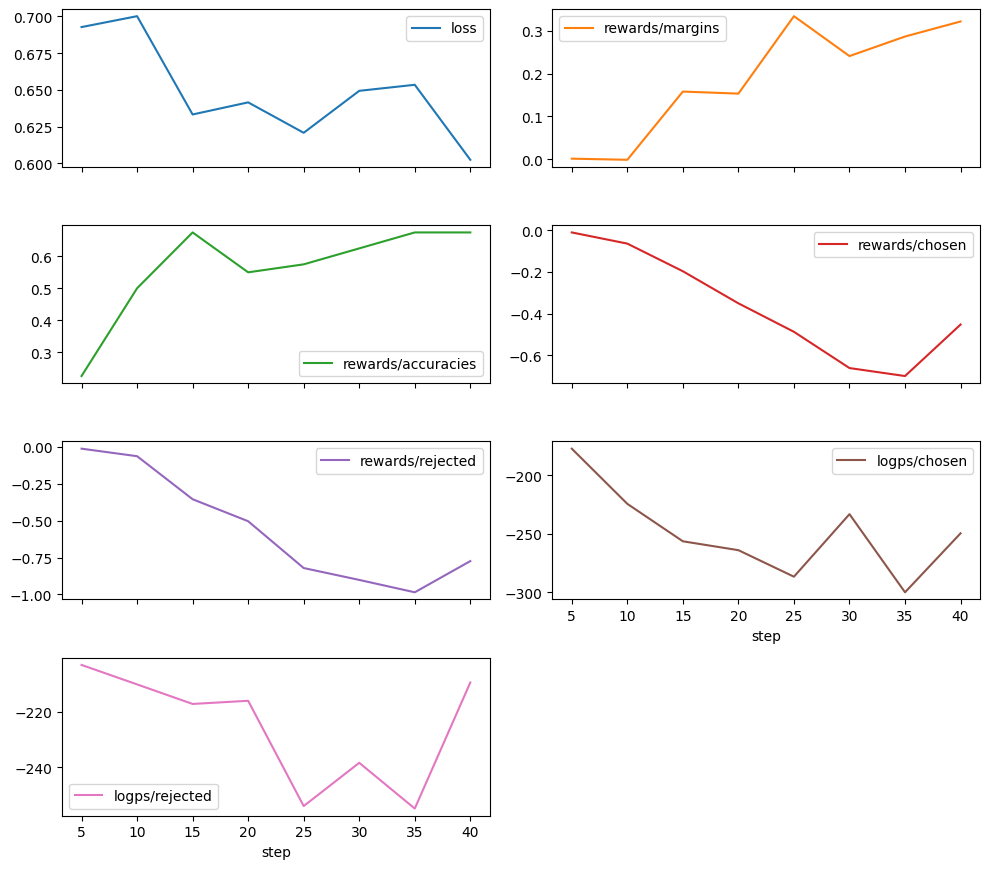

In [ ]:
log = pd.DataFrame([h for h in treinador.state.log_history if "loss" in h and "train_runtime" not in h])
cols = [c for c in ["loss", "rewards/margins", "rewards/accuracies", "rewards/chosen", "rewards/rejected", "logps/chosen", "logps/rejected"] if c in log]
log.plot(x="step", y=cols, subplots=True, layout=(-1, 2), figsize=(10, 2.2 * math.ceil(len(cols) / 2)), legend=True); plt.tight_layout(); plt.show()

✍️ **P4.1** Descreva a evolução de `rewards/accuracies` e `rewards/margins`. As recompensas implícitas de *chosen* sobem ou descem? E `logps/chosen`? Interprete.

**✍️ Resposta:** Nos gráficos, rewards/accuracies sobe aproximadamente de 0,23 para 0,67 e rewards/margins cresce de perto de 0 para 0,32, apesar de algumas oscilações. A recompensa implícita de chosen desce no geral (até cerca de -0,7, recuperando parcialmente no último passo); logps/chosen também fica mais negativo, de cerca de -180 para -250, com uma queda intermédia até perto de -300. Assim, a política melhora a ordenação relativa entre respostas escolhidas e rejeitadas sem necessariamente aumentar a probabilidade absoluta, medida pelo log-prob acumulado, da resposta escolhida. As curvas são ruidosas e devem ser interpretadas como tendência, não como evolução monotónica.

In [ ]:
@torch.no_grad()
def gerar(modelo, prompt, max_new_tokens=150):
    ids = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True, return_tensors="pt").to(modelo.device)
    out = modelo.generate(input_ids=ids.input_ids, attention_mask=ids.attention_mask, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0, ids.input_ids.shape[1]:], skip_special_tokens=True)

m = treinador.model.eval()
for pr in ["Give me three tips to write a good scientific abstract.", "Is it safe to eat raw chicken? Answer briefly."]:
    with m.disable_adapter():
        antes = gerar(m, pr)
    depois = gerar(m, pr)
    print(f"### {pr}\n--- ANTES ({len(antes.split())} palavras)\n{antes}\n--- DEPOIS ({len(depois.split())} palavras)\n{depois}\n")

### Give me three tips to write a good scientific abstract.
--- ANTES (115 palavras)
Certainly! Writing a scientific abstract is crucial for presenting your research effectively and clearly. Here are three key tips to help you create an engaging and informative scientific paper:

1. **Keep it concise**: Scientific papers should be brief but comprehensive. Aim for around 200-300 words per page. This allows readers to quickly grasp the main points of your work without having to read through the entire document.

2. **Use clear and precise language**: Avoid jargon or overly technical terms unless they are essential to understanding the content. Use simple language that is easy for non-specialists to understand. For example, instead of saying "We found [X]," say "We observed [X]."

3. **Provide context and background information
--- DEPOIS (123 palavras)
Writing a scientific abstract is crucial for presenting your research findings clearly and effectively. Here are three key tips to help y

✍️ **P4.2** Que diferenças observa (estilo, estrutura, comprimento)? Com 40 passos, o que é plausível ter mudado e o que não? Como verificaria se há viés de comprimento?

**✍️ Resposta:** No prompt do resumo científico, as respostas mantêm estrutura e estilo muito parecidos (a versão "depois" apenas deixa de abrir com "Certainly!"), e o comprimento muda pouco: 115 palavras antes e 123 depois. No prompt sobre frango cru, passa de 119 para 68 palavras; a resposta posterior começa por dizer que é seguro comer frango cru e depois contradiz isso ao recomendar que seja bem cozinhado, portanto o exemplo não demonstra melhoria de segurança ou factualidade. Nota: as gerações foram limitadas a `max_new_tokens=150`, pelo que várias respostas ficam truncadas e as contagens de palavras não são fiáveis para comparar comprimento. Com apenas 40 passos é plausível observar ajustes locais de estilo e comprimento, mas não uma mudança geral de capacidade ou comportamento. Para testar viés de comprimento, compararia as distribuições de tokens antes e depois em muitos prompts fixos e várias sementes (com um `max_new_tokens` maior, para não truncar), incluindo mediana e quantis, e avaliaria a qualidade com critérios independentes do comprimento.

In [ ]:
#del treinador, modelo, m; gc.collect(); torch.cuda.empty_cache()

## 5 · GRPO com recompensas verificáveis (≈ 20 min, ~8 min de treino)

### 5.1 · Vantagens relativas ao grupo

$$\hat A_i=\frac{r_i-\operatorname{mean}(r)}{\operatorname{std}(r)+\varepsilon}$$

In [ ]:
import os, re, math, random, time, gc
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
USE_FP16, USE_BF16, BF16 = DEVICE == "cuda", False, False   # T4: fp16
tok = AutoTokenizer.from_pretrained(MODELO)
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                  target_modules="all-linear", task_type="CAUSAL_LM")
print("Dispositivo:", DEVICE)

Dispositivo: cuda


In [ ]:
def vantagens_grupo(r, normalizar_std=True, eps=1e-4):
    r = np.asarray(r, dtype=float)
    # TODO: centre pela média do grupo e, opcionalmente, divida pelo desvio-padrão (populacional)
    vantagens = r - r.mean()
    if normalizar_std:
        vantagens = vantagens / (r.std(ddof=0) + eps)
    return vantagens

print(vantagens_grupo([1, 0, 1, 0]).round(3), vantagens_grupo([1, 1, 1, 1]), vantagens_grupo([1, 0, 0, 0]).round(3))
assert np.allclose(vantagens_grupo([1, 0, 1, 0]), [1, -1, 1, -1], atol=1e-3)
assert np.allclose(vantagens_grupo([1, 1, 1, 1]), 0)

[ 1. -1.  1. -1.] [0. 0. 0. 0.] [ 1.732 -0.577 -0.577 -0.577]


✍️ **P5.1** Compare $[1,0,0,0]$ com $[1,1,1,0]$: que resposta recebe a maior vantagem absoluta em cada caso? Porque é que a divisão pelo desvio-padrão cria um viés de dificuldade (Dr. GRPO)?

**✍️ Resposta:** Em [1,0,0,0], a única resposta correta recebe a maior vantagem absoluta: $3/\sqrt{3}\approx1{,}732$; cada incorreta recebe cerca de -0,577. Em [1,1,1,0], acontece o inverso: a única incorreta recebe -1,732 e cada correta 0,577. Dividir pelo desvio-padrão normaliza cada grupo para uma escala semelhante, amplificando resultados raros e fazendo o peso depender da composição/dificuldade do grupo, não só da diferença de recompensa. Assim, uma resposta errada num grupo fácil pode receber uma atualização de grande magnitude; scale_rewards=False evita essa normalização e é a motivação do Dr. GRPO.

### 5.2 · Funções de recompensa

O modelo deve terminar com `Resposta: <número>`. Implemente uma recompensa de **correção** (1,0 ou 0,0) e uma de **formato** (0,2). Na TRL, cada função recebe `completions` (lista de mensagens) e as colunas do dataset como argumentos nomeados.

In [ ]:
SISTEMA = "Resolve o problema passo a passo e termina com uma linha no formato 'Resposta: <número>'."
RE_RESP = re.compile(r"Resposta:\s*\$?\s*(-?[\d.,]+)", re.IGNORECASE)

def _texto(c):
    return c[0]["content"] if isinstance(c, list) else c

def extrair_numero(texto):
    m = RE_RESP.findall(texto)
    if not m:
        return None
    try:
        return float(m[-1].replace(",", "").rstrip("."))
    except ValueError:
        return None

def recompensa_correcao(completions, resposta, **kwargs):
    # TODO: 1.0 se o último número após "Resposta:" coincidir com a resposta de referência, senão 0.0
    recompensas = []
    for completion, referencia in zip(completions, resposta):
        numero = extrair_numero(_texto(completion))
        try:
            esperado = float(str(referencia).replace(",", "").strip())
        except ValueError:
            esperado = None
        recompensas.append(1.0 if numero is not None and numero == esperado else 0.0)
    return recompensas

def recompensa_formato(completions, **kwargs):
    return [0.2 if RE_RESP.search(_texto(c)) else 0.0 for c in completions]

testes = [[{"role": "assistant", "content": "3 + 4 = 7.\nResposta: 7"}],
          [{"role": "assistant", "content": "Acho que é 8.\nResposta: 8."}],
          [{"role": "assistant", "content": "São 1,000 euros. Resposta: $1,000"}],
          [{"role": "assistant", "content": "A resposta é 7."}]]
print(recompensa_correcao(testes, ["7", "7", "1000", "7"]), recompensa_formato(testes))
assert recompensa_correcao(testes, ["7", "7", "1000", "7"]) == [1.0, 0.0, 1.0, 0.0]

[1.0, 0.0, 1.0, 0.0] [0.2, 0.2, 0.2, 0.0]


✍️ **P5.2** Encontre pelo menos **duas** formas de a política obter recompensa sem resolver o problema, ou de ser penalizada injustamente (ex.: decimais com vírgula em português). Como corrigiria?

**✍️ Resposta:** Há pelo menos três fragilidades. Primeiro, a recompensa de formato pode ser obtida sem resolver nada: basta escrever Resposta: 42; separaria a pontuação de formato da correção ou daria o bónus de formato apenas quando a resposta também é validada. Segundo, extrair_numero remove todas as vírgulas, pelo que 1,5 passa a 15; a convenção decimal deve ser definida pela língua/dataset e validada com Decimal, rejeitando casos ambíguos. Terceiro, a comparação exata de float pode penalizar respostas numericamente equivalentes com arredondamento, unidades ou frações; deve-se normalizar unidades e usar uma tolerância explícita quando a tarefa o permitir. A extração também não verifica o raciocínio: alguém pode adivinhar ou memorizar o valor final e receber a recompensa de correção.

In [ ]:
from trl import GRPOConfig, GRPOTrainer

def preparar(ex):
    return {"prompt": [{"role": "system", "content": SISTEMA}, {"role": "user", "content": ex["question"]}],
            "resposta": ex["answer"].split("####")[-1].strip().replace(",", "")}

gsm = load_dataset("openai/gsm8k", "main")
treino = gsm["train"].shuffle(seed=0).select(range(400)).map(preparar, remove_columns=["question", "answer"])
teste = gsm["test"].shuffle(seed=0).select(range(30)).map(preparar, remove_columns=["question", "answer"])

@torch.no_grad()
def exatidao(modelo, dados, max_new_tokens=256):
    modelo.eval(); acertos, formato = 0, 0
    for ex in dados:
        enc = tok.apply_chat_template(ex["prompt"], add_generation_prompt=True,
                                      return_tensors="pt", return_dict=True).to(modelo.device)
        n = enc["input_ids"].shape[1]
        saida = modelo.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        out = tok.decode(saida[0, n:], skip_special_tokens=True)
        acertos += recompensa_correcao([out], [ex["resposta"]])[0]
        formato += recompensa_formato([out])[0] > 0
    return acertos / len(dados), formato / len(dados)

modelo = AutoModelForCausalLM.from_pretrained(MODELO, dtype=torch.bfloat16 if BF16 else torch.float32).to(DEVICE)
acc0 = exatidao(modelo, teste); print(f"ANTES — exatidão: {acc0[0]:.0%} | formato: {acc0[1]:.0%}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

ANTES — exatidão: 0% | formato: 7%


In [ ]:
from trl import GRPOConfig, GRPOTrainer

cfg_grpo = GRPOConfig(
    output_dir="grpo-qwen05", learning_rate=2e-5, lr_scheduler_type="constant",
    per_device_train_batch_size=8, gradient_accumulation_steps=1, num_generations=4,
    max_completion_length=256, temperature=1.0,
    beta=0.04, loss_type="grpo", max_steps=40, gradient_checkpointing=True,
    bf16=USE_BF16, fp16=USE_FP16,
    logging_steps=5, save_strategy="no", report_to="none",
)
treinador = GRPOTrainer(model=modelo, reward_funcs=[recompensa_correcao, recompensa_formato],
                        args=cfg_grpo, train_dataset=treino, processing_class=tok, peft_config=lora)
treinador.train()

Step,Training Loss
5,0.000443
10,0.001404
15,0.002682
20,0.003287
25,0.002022
30,0.001408
35,0.001545
40,0.001264


TrainOutput(global_step=40, training_loss=0.0017570038326084614, metrics={'train_runtime': 169.667, 'train_samples_per_second': 1.886, 'train_steps_per_second': 0.236, 'total_flos': 0.0, 'train_loss': 0.0017570038326084614, 'epoch': 0.2})

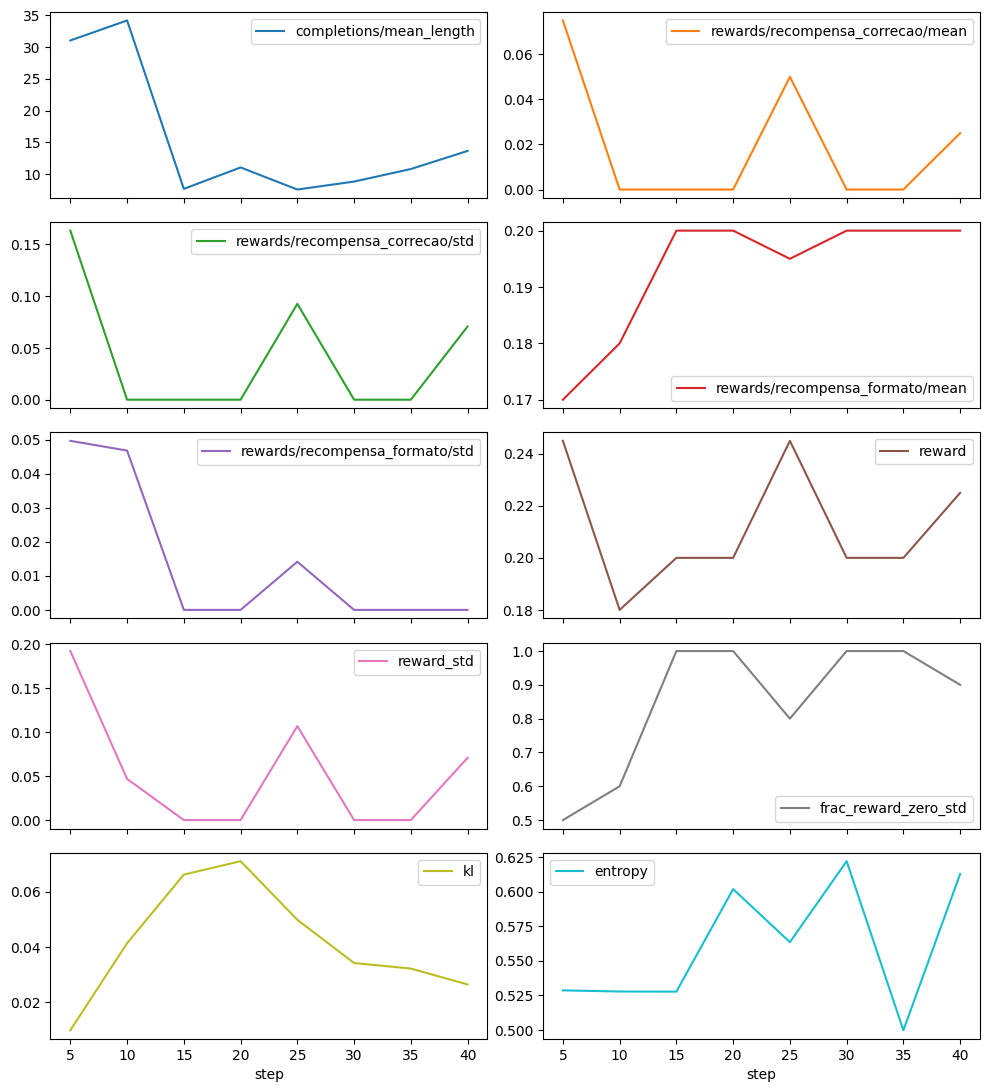

ANTES  — exatidão: 0% | formato: 7%
DEPOIS — exatidão: 3% | formato: 100%


In [ ]:
log = pd.DataFrame([h for h in treinador.state.log_history if "train_runtime" not in h])
cols = [c for c in log.columns if any(k in c for k in ["reward", "kl", "mean_length", "zero_std", "entropy"]) and log[c].notna().any()]
log.plot(x="step", y=cols, subplots=True, layout=(-1, 2), figsize=(10, 2.2 * math.ceil(len(cols) / 2))); plt.tight_layout(); plt.show()
acc1 = exatidao(treinador.model, teste)
print(f"ANTES  — exatidão: {acc0[0]:.0%} | formato: {acc0[1]:.0%}\nDEPOIS — exatidão: {acc1[0]:.0%} | formato: {acc1[1]:.0%}")

✍️ **P5.3** Interprete as curvas: recompensa média, `reward_std`, fração de grupos com desvio nulo, KL e comprimento. A melhoria (se houver) vem da correção ou do formato? Com 30 exemplos de teste, quão confiável é a diferença?

**✍️ Resposta:** A recompensa de formato sobe de cerca de 0,17 para 0,20 e fica nesse patamar; a recompensa de correção é esparsa e quase sempre zero, pelo que a recompensa média acompanha sobretudo o formato. `reward_std` cai frequentemente a zero e a fração de grupos com desvio nulo chega a 1 em vários passos: as respostas do grupo recebem recompensas iguais, logo as vantagens são nulas e não há sinal de aprendizagem. O comprimento médio cai de cerca de 31–34 para 8–14 tokens, o que sugere que o modelo deixou de raciocinar passo a passo e passou a escrever quase só "Resposta: N", isto é, está a explorar a recompensa de formato, que é fácil de obter. A KL aumenta até aproximadamente 0,07 e depois recua para cerca de 0,03; a entropia oscila entre cerca de 0,50 e 0,62, sem tendência monotónica clara. No teste, a exatidão passou de 0 % para 3 % (um acerto em 30), enquanto o formato subiu de 7 % para 100 %; a melhoria é sobretudo de formato, sem evidência convincente de melhoria de correção. Com 30 exemplos e uma semente, um único acerto não permite concluir que a exatidão melhorou de forma fiável; seria preciso um conjunto maior e várias sementes.

## 6 · Desafios extra (para quem terminar cedo ou como trabalho de casa)

1. **Dr. GRPO vs GRPO:** repita a Parte 5 com `loss_type="dr_grpo"` e `scale_rewards=False`. Compare o comprimento das respostas.
2. **β = 0:** treine o GRPO sem KL. O que acontece à entropia e ao KL implícito?
3. **IPO:** na Parte 4, use `loss_type="ipo"` no `DPOConfig` e compare `logps/chosen`.
4. **Português:** adapte os filtros da Parte 1 a português (stopwords, comprimento médio) e meça quantos originais deixam de ser removidos.
5. **Hacking:** suba a recompensa de formato para 1,0 e observe se a correção piora.

## 📦 Entrega

Submeta este notebook **executado**, com todas as células ✍️ respondidas, até ao fim da semana. Critérios: código correto (40 %), qualidade das respostas e interpretação dos gráficos (45 %), desafio extra (15 %).